# Notebook 06 — VaR Backtesting

Estimating Value at Risk is only the first step. A risk model should also be tested to determine whether its predictions are consistent with actual market outcomes.

In this notebook, VaR and Expected Shortfall (ES) are recalculated each day using a rolling one-year estimation window for three methods — Historical Simulation, Parametric and EWMA — and compared against realised portfolio returns. Each forecast for date t uses only information available through t-1, avoiding look-ahead bias, and all methods are evaluated on exactly the same dates.

Three validation tests are applied to each method:
- The **Kupiec Proportion of Failures (POF) test** checks whether the number of VaR breaches is statistically consistent with the stated confidence level.
- The **Christoffersen Independence test** checks whether breaches cluster in time rather than occurring independently — a model can have the right breach *count* while still failing if breaches bunch together during volatile periods.
- The **combined (conditional coverage) test** checks frequency and independence together.

An **ES tail check** compares, on breach days, the actual loss with the ES the model forecast for that day (a ratio near 1 means the ES estimate was realistic).

Monte Carlo is not backtested separately: it draws from the same fitted normal distribution as the Parametric method, so its VaR converges to Parametric's and a separate backtest would simply repeat the Parametric result.

**Return convention:** the portfolio return is the weighted sum of asset simple (percentage) daily returns; a breach is a day whose loss exceeds that day's VaR forecast.

## Outputs

- Rolling VaR for Historical, Parametric and EWMA
- Kupiec, Christoffersen and combined test results per method
- ES tail check per method
- Comparative summary table and computed key findings


Forecasts per method: 2264 (2015-12-31 to 2024-12-30)

Model Validation Summary
               Expected  Observed Kupiec p Kupiec Chris p Christoffersen Combined p    Verdict
Method     CL                                                                                 
Historical 95%    113.2       109   0.6837   PASS  0.0002           FAIL     0.0009  CLUSTERED
           99%     22.6        36   0.0094   FAIL  0.0199           FAIL     0.0023       FAIL
Parametric 95%    113.2       105   0.4237   PASS  0.0001           FAIL     0.0003  CLUSTERED
           99%     22.6        59   0.0000   FAIL  0.0000           FAIL     0.0000       FAIL
EWMA       95%    113.2       108   0.6135   PASS  0.4158           PASS     0.6322       PASS
           99%     22.6        51   0.0000   FAIL  0.1384           PASS     0.0000       FAIL

Verdict: PASS = both tests pass
         CLUSTERED = Kupiec passes, Christoffersen fails (right number of breaches, but bunched)
         FAIL = Kupiec fails



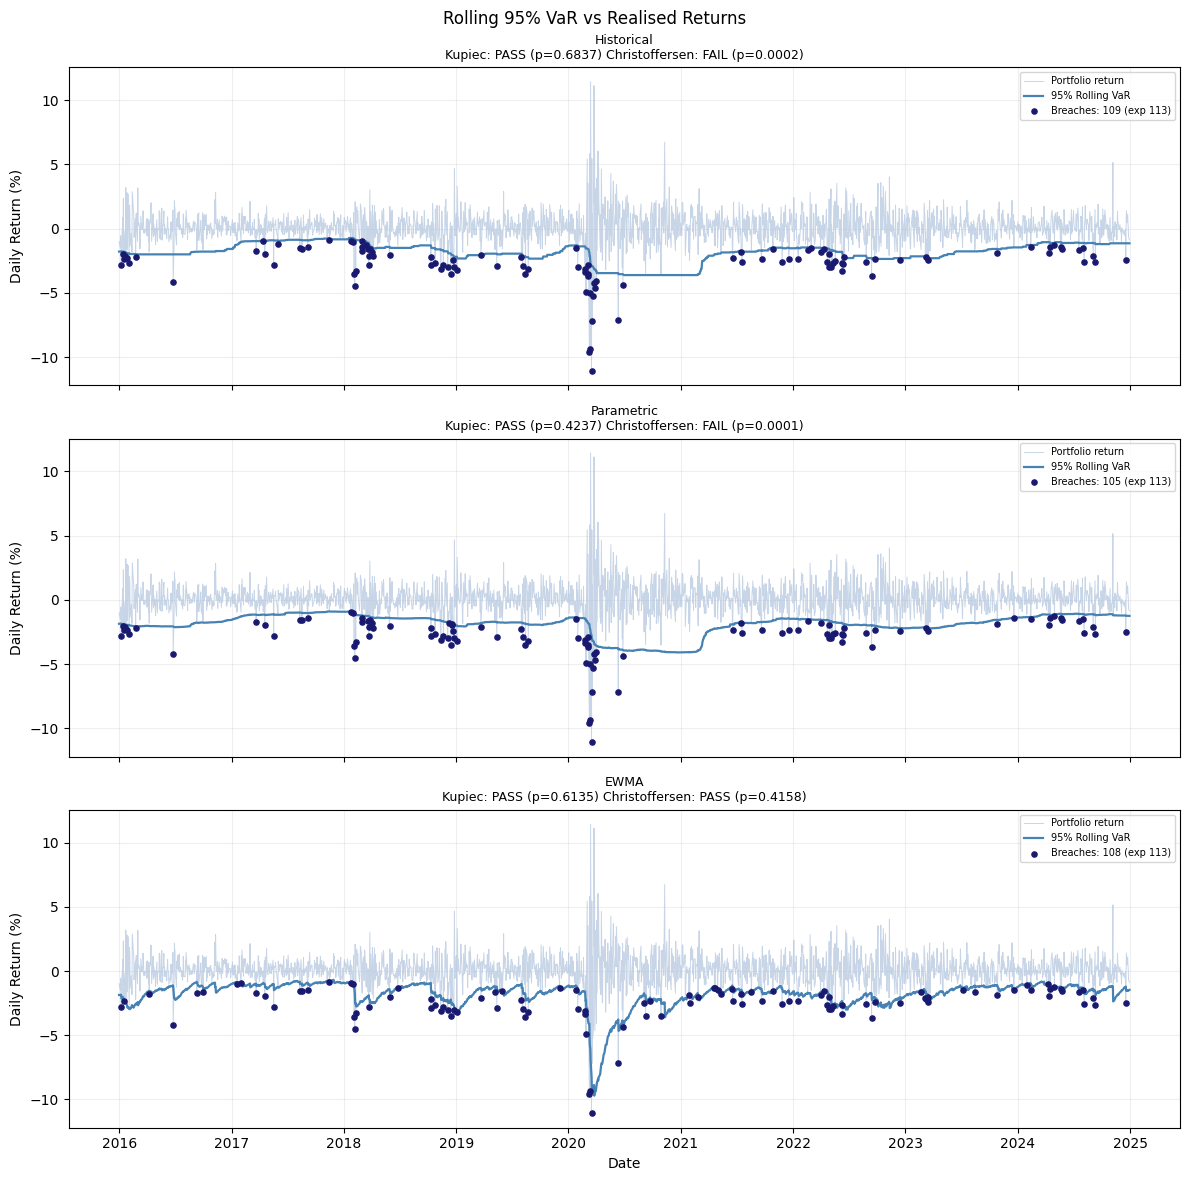

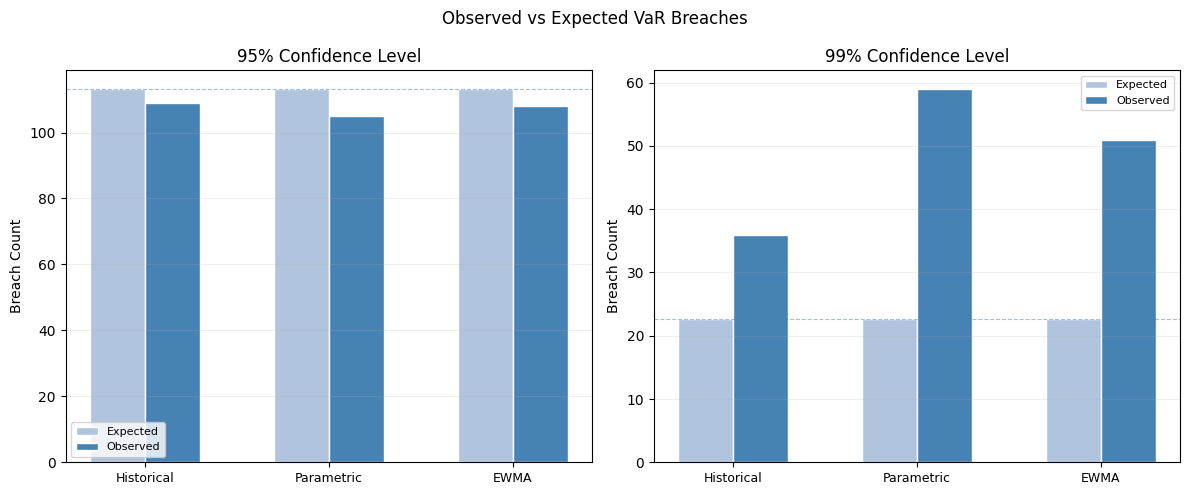

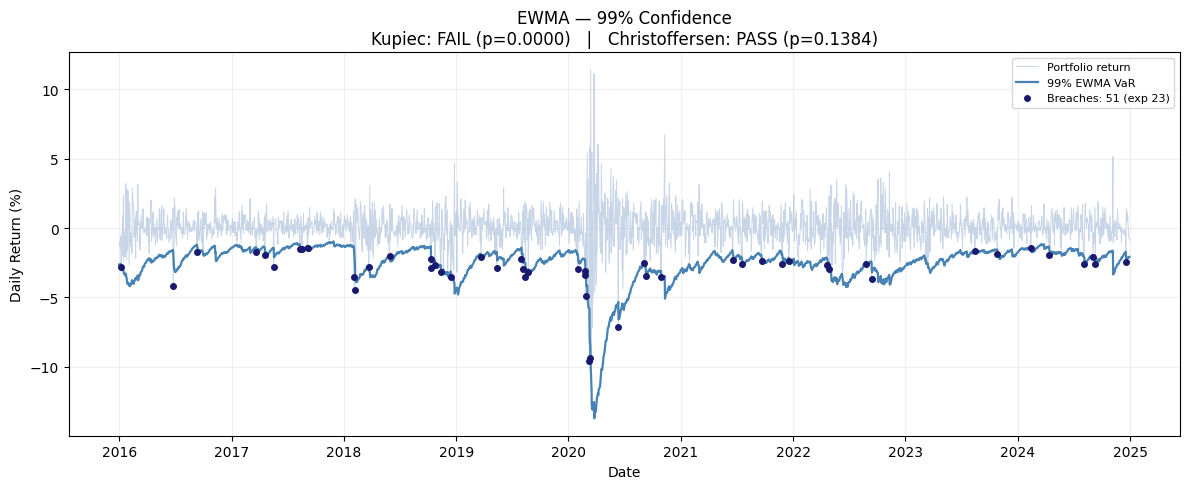

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import xlogy
from scipy.stats import chi2, norm

pd.set_option('display.float_format', '{:.4f}'.format)

# Configuration

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
confidence_levels = [0.95, 0.99]
portfolio_value = 1_000_000
rolling_window  = 250
lam  = 0.94

log_returns = pd.read_csv('../data/log_returns.csv', index_col=0, parse_dates=True)
assert log_returns.isna().sum().sum() == 0

# Portfolio return = weighted sum of asset simple (percentage) returns
simple_returns = np.exp(log_returns) - 1
portfolio_returns = simple_returns.dot(weights)


# Rolling forecasts.
# The value at date t is a forecast made with information through t-1 only.

def rolling_historical_var(returns, window, confidence):
    return returns.rolling(window).apply(
        lambda x: -np.percentile(x, (1 - confidence) * 100), raw=True).shift(1)


def rolling_parametric_var(returns, window, confidence):
    z  = norm.ppf(1 - confidence)
    mu = returns.rolling(window).mean()
    sg = returns.rolling(window).std()
    return (-(mu + z * sg)).shift(1)


def rolling_ewma_var(returns, window, confidence, lam=0.94):
    z = norm.ppf(1 - confidence)
    r = returns.values
    n = len(r)
    ewma_var_arr = np.full(n, np.nan)
    ewma_var_arr[window] = np.var(r[:window])
    for t in range(window + 1, n):
        ewma_var_arr[t] = lam * ewma_var_arr[t - 1] + (1 - lam) * r[t - 1] ** 2
    # ewma_var_arr[t] already uses returns only through t-1, so no further shift.
    return pd.Series(-z * np.sqrt(ewma_var_arr), index=returns.index)


def rolling_historical_es(returns, window, confidence):
    q = (1 - confidence) * 100
    return returns.rolling(window).apply(
        lambda x: -x[x <= np.percentile(x, q)].mean(), raw=True).shift(1)


def rolling_parametric_es(returns, window, confidence):
    z  = norm.ppf(1 - confidence)
    mu = returns.rolling(window).mean()
    sg = returns.rolling(window).std()
    return (-mu + sg * norm.pdf(z) / (1 - confidence)).shift(1)


def rolling_ewma_es(returns, window, confidence, lam=0.94):
    z = norm.ppf(1 - confidence)
    vol = rolling_ewma_var(returns, window, confidence, lam) / (-z)
    return vol * norm.pdf(z) / (1 - confidence)


# Statistical tests

def kupiec_test(n_obs, n_breaches, confidence):
    # H0: observed breach rate equals the stated tail probability.
    # LR ~ chi2(1) under H0. xlogy(0, 0) = 0, so zero breaches is handled.
    p = 1 - confidence
    p_hat = n_breaches / n_obs
    lr = -2 * (xlogy(n_breaches, p) + xlogy(n_obs - n_breaches, 1 - p)
               - xlogy(n_breaches, p_hat) - xlogy(n_obs - n_breaches, 1 - p_hat))
    lr = max(lr, 0.0)
    p_value = chi2.sf(lr, df=1)
    return lr, p_value, p_value > 0.05


def christoffersen_test(breaches):
    # H0: breaches are serially independent. LR ~ chi2(1) under H0.
    # Compares P(breach | breach yesterday) with P(breach | no breach yesterday).
    b = breaches.values
    n00 = sum(1 for t in range(1, len(b)) if b[t-1]==0 and b[t]==0)
    n01 = sum(1 for t in range(1, len(b)) if b[t-1]==0 and b[t]==1)
    n10 = sum(1 for t in range(1, len(b)) if b[t-1]==1 and b[t]==0)
    n11 = sum(1 for t in range(1, len(b)) if b[t-1]==1 and b[t]==1)
    n = n00 + n01 + n10 + n11
    pi01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    pi   = (n01 + n11) / n
    ll_null = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll_alt = (xlogy(n00, 1 - pi01) + xlogy(n01, pi01)
              + xlogy(n10, 1 - pi11) + xlogy(n11, pi11))
    lr = max(-2 * (ll_null - ll_alt), 0.0)
    p_value = chi2.sf(lr, df=1)
    return lr, p_value, p_value > 0.05


# Run backtests
methods = {
    'Historical': rolling_historical_var,
    'Parametric': rolling_parametric_var,
    'EWMA':       rolling_ewma_var,}

es_methods = {
    'Historical': rolling_historical_es,
    'Parametric': rolling_parametric_es,
    'EWMA':       rolling_ewma_es,}

results = {}

for name, fn in methods.items():
    results[name] = {}
    for cl in confidence_levels:
        vs      = fn(portfolio_returns, rolling_window, cl)
        es      = es_methods[name](portfolio_returns, rolling_window, cl)
        valid   = vs.dropna()
        aligned = portfolio_returns.loc[valid.index]
        loss    = -aligned
        breach  = (loss > valid).astype(int)
        n       = len(valid)
        nb      = int(breach.sum())
        exp     = n * (1 - cl)

        lr_k, pv_k, pass_k = kupiec_test(n, nb, cl)
        lr_c, pv_c, pass_c = christoffersen_test(breach)
        pv_cc = chi2.sf(lr_k + lr_c, df=2)

        b = breach == 1
        es_valid = es.loc[valid.index]
        verdict = ('PASS' if pass_k and pass_c
                   else 'CLUSTERED' if pass_k
                   else 'FAIL')

        results[name][cl] = {
            'var_series':    valid,
            'breaches':      breach,
            'n_obs':         n,
            'n_breaches':    nb,
            'expected':      exp,
            'kupiec_lr':     lr_k,
            'kupiec_pval':   pv_k,
            'kupiec_pass':   pass_k,
            'chris_lr':      lr_c,
            'chris_pval':    pv_c,
            'chris_pass':    pass_c,
            'cc_pval':       pv_cc,
            'verdict':       verdict,
            'avg_loss_breach': loss[b].mean() if b.any() else np.nan,
            'avg_es_breach':   es_valid[b].mean() if b.any() else np.nan,
            'es_ratio':        (loss[b] / es_valid[b]).mean() if b.any() else np.nan,}

# All methods must be evaluated on exactly the same dates
first = next(iter(results.values()))
for name in results:
    for cl in confidence_levels:
        assert results[name][cl]['var_series'].index.equals(first[cl]['var_series'].index)

print(f"Forecasts per method: {first[0.95]['n_obs']} "
      f"({first[0.95]['var_series'].index[0].date()} to {first[0.95]['var_series'].index[-1].date()})")


# Consolidated validation table
rows = []
for name in methods:
    for cl in confidence_levels:
        r = results[name][cl]
        rows.append({
            'Method':        name,
            'CL':            f"{cl*100:.0f}%",
            'Expected':      f"{r['expected']:.1f}",
            'Observed':      r['n_breaches'],
            'Kupiec p':      f"{r['kupiec_pval']:.4f}",
            'Kupiec':        'PASS' if r['kupiec_pass'] else 'FAIL',
            'Chris p':       f"{r['chris_pval']:.4f}",
            'Christoffersen':'PASS' if r['chris_pass'] else 'FAIL',
            'Combined p':    f"{r['cc_pval']:.4f}",
            'Verdict':       r['verdict'],})

val_table = pd.DataFrame(rows).set_index(['Method', 'CL'])
print("\nModel Validation Summary")
print("=" * 100)
print(val_table.to_string())
print("=" * 100)
print()
print("Verdict: PASS = both tests pass")
print("         CLUSTERED = Kupiec passes, Christoffersen fails (right number of breaches, but bunched)")
print("         FAIL = Kupiec fails")

# ES tail check
es_rows = []
for name in methods:
    for cl in confidence_levels:
        r = results[name][cl]
        es_rows.append({
            'Method': name,
            'CL': f"{cl*100:.0f}%",
            'Breach days': r['n_breaches'],
            'Avg actual loss': f"{r['avg_loss_breach']*100:.2f}%",
            'Avg forecast ES': f"{r['avg_es_breach']*100:.2f}%",
            'Actual / forecast': f"{r['es_ratio']:.2f}x",})
print("\nES tail check (on breach days: actual loss vs the ES forecast for that day; 1.00x = realistic)")
print(pd.DataFrame(es_rows).set_index(['Method', 'CL']).to_string())

# Key findings, computed from the results
print("\nKey findings (computed from the results above):")
for cl in confidence_levels:
    passing  = [m for m in methods if results[m][cl]['verdict'] == 'PASS']
    too_many = [m for m in methods if (not results[m][cl]['kupiec_pass'])
                and results[m][cl]['n_breaches'] > results[m][cl]['expected']]
    spread   = [m for m in methods if results[m][cl]['chris_pass']]
    print(f"  {cl*100:.0f}% confidence:")
    print(f"    passes both tests              : {', '.join(passing) if passing else 'none'}")
    print(f"    too many breaches (VaR too low): {', '.join(too_many) if too_many else 'none'}")
    print(f"    breaches not clustered         : {', '.join(spread) if spread else 'none'}")


# Visualisation

# Figure 1: Rolling VaR vs realised returns, 95% confidence.

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
fig.suptitle("Rolling 95% VaR vs Realised Returns", fontsize=12)

for ax, name in zip(axes.flat, methods):
    r = results[name][0.95]
    dates = r['var_series'].index
    breach_dates = r['breaches'][r['breaches'] == 1].index

    ax.plot(dates,
            portfolio_returns.loc[dates] * 100,
            color='lightsteelblue', linewidth=0.7, alpha=0.7,
            label='Portfolio return')

    ax.plot(dates,
            -r['var_series'] * 100,
            color='steelblue', linewidth=1.6,
            label='95% Rolling VaR')

    ax.scatter(breach_dates,
               portfolio_returns.loc[breach_dates] * 100,
               color='midnightblue', s=14, zorder=5,
               label=f"Breaches: {r['n_breaches']} "
                     f"(exp {r['expected']:.0f})")

    k = 'PASS' if r['kupiec_pass'] else 'FAIL'
    c = 'PASS' if r['chris_pass']  else 'FAIL'

    ax.set_title(
        f"{name}\n"
        f"Kupiec: {k} (p={r['kupiec_pval']:.4f}) "
        f"Christoffersen: {c} (p={r['chris_pval']:.4f})", fontsize=9)
    ax.set_ylabel("Daily Return (%)")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")

plt.tight_layout()
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/06_backtesting.png', dpi=150, bbox_inches='tight')
plt.show()


# Figure 2: Observed vs expected breach counts, both confidence levels.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Observed vs Expected VaR Breaches", fontsize=12)

m_names = list(methods.keys())
x  = np.arange(len(m_names))
w  = 0.30

for ax, cl in zip(axes, confidence_levels):
    exp_vals = [results[m][cl]['expected']   for m in m_names]
    obs_vals = [results[m][cl]['n_breaches'] for m in m_names]

    ax.bar(x - w/2, exp_vals, w,
           label='Expected', color='lightsteelblue',
           edgecolor='white')
    ax.bar(x + w/2, obs_vals, w,
           label='Observed', color='steelblue',
           edgecolor='white')

    ax.axhline(exp_vals[0], color='steelblue',
               linewidth=0.8, linestyle='--', alpha=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(m_names, fontsize=9)
    ax.set_ylabel("Breach Count")
    ax.set_title(f"{cl*100:.0f}% Confidence Level")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2, axis='y')

plt.tight_layout()
plt.savefig('../reports/06_backtesting_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


# Figure 3: Breach timeline for EWMA at 99%.

fig, ax = plt.subplots(figsize=(12, 5))

r  = results['EWMA'][0.99]
dates = r['var_series'].index
breach_dates = r['breaches'][r['breaches'] == 1].index

ax.plot(dates,
        portfolio_returns.loc[dates] * 100,
        color='lightsteelblue', linewidth=0.7, alpha=0.7,
        label='Portfolio return')

ax.plot(dates,
        -r['var_series'] * 100,
        color='steelblue', linewidth=1.6,
        label='99% EWMA VaR')

ax.scatter(breach_dates,
           portfolio_returns.loc[breach_dates] * 100,
           color='midnightblue', s=16, zorder=5,
           label=f"Breaches: {r['n_breaches']} "
                 f"(exp {r['expected']:.0f})")

k_txt = 'PASS' if r['kupiec_pass'] else 'FAIL'
c_txt = 'PASS' if r['chris_pass'] else 'FAIL'
ax.set_title(
    "EWMA — 99% Confidence\n"
    f"Kupiec: {k_txt} (p={r['kupiec_pval']:.4f})   |   "
    f"Christoffersen: {c_txt} (p={r['chris_pval']:.4f})")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Return (%)")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig('../reports/06_backtesting_ewma_99.png', dpi=150, bbox_inches='tight')
plt.show()
